# Drug Consumption Risk Prediction: Cannabis

This notebook trains a model to predict whether someone uses a drug, based on their
personality traits and basic demographics (age, gender, education, country, ethnicity).

The real point of this notebook isn't just accuracy. It's explainability. We use two
different explanation methods, **SHAP** and **LIME**, to see which features actually drive
the model's predictions, and then check whether the two methods agree with each other.

We do the full thing once for **Cannabis** (a single drug), then repeat a shorter version
for **Depressants** (a drug category made up of Benzodiazepines, Heroin and Methadone).

Dataset: `Drug_Consumption.csv`, sitting in the same folder as this notebook. It's the UCI
Drug Consumption dataset, 1,884 participants, 12 personality/demographic features and usage
history for 18 substances plus one fake control drug (Semeron).

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from scipy.stats import spearmanr

import shap
from lime.lime_tabular import LimeTabularExplainer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the data

Age, Gender, Education, Country and Ethnicity are already given to us as readable text
(not the coded numbers from the original UCI release), and each drug column uses a
0-6 scale (`CL0` = never used, `CL6` = used in the last day).

In [2]:
df = pd.read_csv("Drug_Consumption.csv")
print("Rows, columns:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.head()

Rows, columns: (1884, 32)
Missing values: 0
Duplicate rows: 0


,ID,Age,Gender,Education,Country,Ethnicity,Nscore,Escore,Oscore,AScore,...,Ecstasy,Heroin,Ketamine,Legalh,LSD,Meth,Mushrooms,Nicotine,Semer,VSA
0,2,25-34,M,Doctorate degree,UK,White,-0.67825,1.93886,1.43533,0.76096,...,CL4,CL0,CL2,CL0,CL2,CL3,CL0,CL4,CL0,CL0
1,3,35-44,M,Professional certificate/ diploma,UK,White,-0.46725,0.80523,-0.84732,-1.62090,...,CL0,CL0,CL0,CL0,CL0,CL0,CL1,CL0,CL0,CL0
2,4,18-24,F,Masters degree,UK,White,-0.14882,-0.80615,-0.01928,0.59042,...,CL0,CL0,CL2,CL0,CL0,CL0,CL0,CL2,CL0,CL0
3,5,35-44,F,Doctorate degree,UK,White,0.73545,-1.63340,-0.45174,-0.30172,...,CL1,CL0,CL0,CL1,CL0,CL0,CL2,CL2,CL0,CL0
4,6,65+,F,Left school at 18 years,Canada,White,-0.67825,-0.30033,-1.55521,2.03972,...,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL6,CL0,CL0


## 3. Turn it into numbers the model can use

Age and Education have a natural order, so we encode them as ordinal numbers.
Gender becomes 0/1. Country and Ethnicity don't have an order, so they get one-hot
encoded (turned into a column per category). Nscore, Escore, Oscore, AScore, Cscore,
Impulsive and SS are already numeric personality scores, so we leave those alone.

In [3]:
demo_cols = ["Age", "Gender", "Education", "Country", "Ethnicity"]
personality_cols = ["Nscore", "Escore", "Oscore", "AScore", "Cscore", "Impulsive", "SS"]
drug_cols = ["Alcohol","Amphet","Amyl","Benzos","Caff","Cannabis","Choc","Coke","Crack",
             "Ecstasy","Heroin","Ketamine","Legalh","LSD","Meth","Mushrooms","Nicotine",
             "Semer","VSA"]

data = df.drop(columns=["ID"]).copy()

age_order = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
edu_order = [
    "Left school before 16 years", "Left school at 16 years", "Left school at 17 years",
    "Left school at 18 years", "Some college or university, no certificate or degree",
    "Professional certificate/ diploma", "University degree", "Masters degree", "Doctorate degree",
]

data["Age_ord"] = data["Age"].apply(lambda x: age_order.index(x))
data["Education_ord"] = data["Education"].apply(lambda x: edu_order.index(x))
data["Gender_bin"] = data["Gender"].map({"M": 0, "F": 1})

country_dummies = pd.get_dummies(data["Country"], prefix="Country", drop_first=True)
ethnicity_dummies = pd.get_dummies(data["Ethnicity"], prefix="Ethnicity", drop_first=True)

feature_frame = pd.concat(
    [data[["Age_ord", "Gender_bin", "Education_ord"] + personality_cols], country_dummies, ethnicity_dummies],
    axis=1,
).astype(float)

print("Feature matrix:", feature_frame.shape)
feature_frame.head()

Feature matrix: (1884, 22)


,Age_ord,Gender_bin,Education_ord,Nscore,Escore,Oscore,AScore,Cscore,Impulsive,SS,...,Country_Other,Country_Republic of Ireland,Country_UK,Country_USA,Ethnicity_Black,Ethnicity_Mixed-Black/Asian,Ethnicity_Mixed-White/Asian,Ethnicity_Mixed-White/Black,Ethnicity_Other,Ethnicity_White
0,1.0,0.0,8.0,-0.67825,1.93886,1.43533,0.76096,-0.14277,-0.71126,-0.21575,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2.0,0.0,5.0,-0.46725,0.80523,-0.84732,-1.62090,-1.01450,-1.37983,0.40148,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,1.0,7.0,-0.14882,-0.80615,-0.01928,0.59042,0.58489,-1.37983,-1.18084,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2.0,1.0,8.0,0.73545,-1.63340,-0.45174,-0.30172,1.30612,-0.21712,-0.21575,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,5.0,1.0,3.0,-0.67825,-0.30033,-1.55521,2.03972,1.63088,-1.37983,-1.54858,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


A participant counts as a "User" of a drug if their answer is `CL2` or higher
(used at some point in the last decade). `CL0` (never) and `CL1` (over a decade ago)
count as "Non-user". This cutoff is what the rest of the notebook uses everywhere.

In [4]:
USER_CLASSES = ["CL2", "CL3", "CL4", "CL5", "CL6"]

def binary_target(column):
    return data[column].isin(USER_CLASSES).astype(int)

## 4. A quick look before modelling

Just to sanity-check the data and get a feel for who's in it, before jumping into the
model. This also gives a first hint at which personality traits might matter for
Cannabis use.

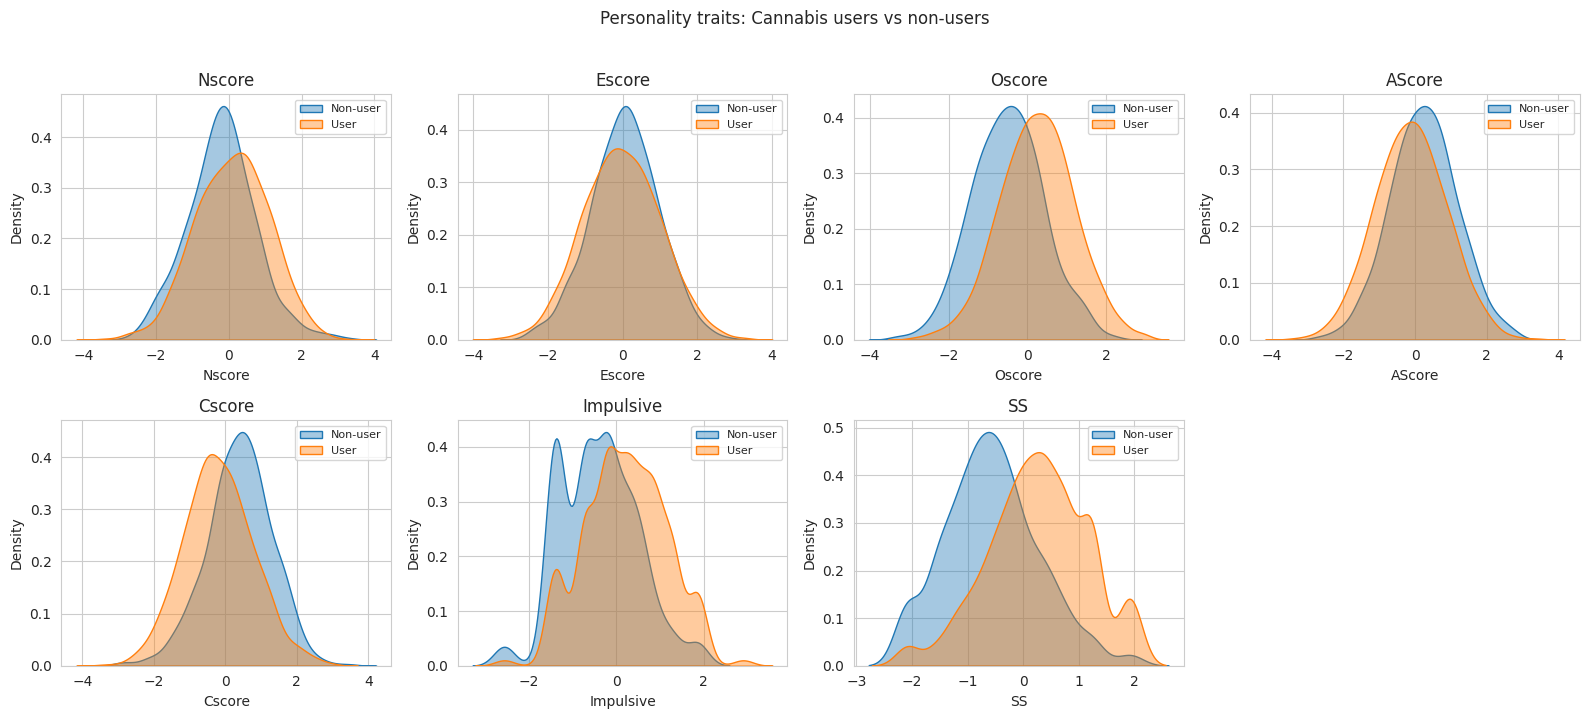

In [5]:
cannabis_user = data["Cannabis"].isin(USER_CLASSES)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), personality_cols):
    sns.kdeplot(data.loc[~cannabis_user, col], ax=ax, label="Non-user", fill=True, alpha=0.4)
    sns.kdeplot(data.loc[cannabis_user, col], ax=ax, label="User", fill=True, alpha=0.4)
    ax.set_title(col)
    ax.legend(fontsize=8)
axes.ravel()[-1].axis("off")
plt.suptitle("Personality traits: Cannabis users vs non-users", y=1.02)
plt.tight_layout()
plt.show()

Users lean a bit higher on Sensation-Seeking and Openness, and a bit lower on Conscientiousness. Worth remembering, since we'll see these same traits show up again once SHAP and LIME weigh in.

# Part 1: Cannabis

We picked Cannabis to run the full pipeline on because it's the most evenly
split drug in the dataset (about 67% users, 33% non-users), which gives the model,
and the explainers, enough examples of both classes to actually learn from.

## 5. Split into train and test

In [6]:
TARGET = "Cannabis"
y = binary_target(TARGET)
X = feature_frame.copy()

print(y.value_counts(normalize=True).rename({0: "Non-user", 1: "User"}).round(3))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Cannabis
User        0.671
Non-user    0.329
Name: proportion, dtype: float64
Train: (1507, 22)  Test: (377, 22)


## 6. Balance the training set (SMOTE)

67/33 isn't terrible, but the model still leans toward the bigger class if we don't
fix it. SMOTE makes synthetic examples of the smaller class so training is balanced
50/50. Important: this is only done to the training data. The test set stays exactly
as it was, so evaluation is still realistic.

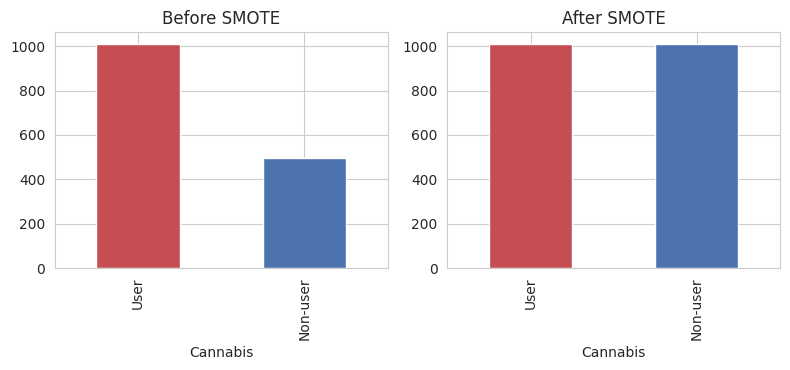

Before: {'User': 1012, 'Non-user': 495}  After: {'User': 1012, 'Non-user': 1012}


In [7]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

X_train_bal, y_train_bal = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_scaled, y_train)

before = y_train.value_counts().rename({0: "Non-user", 1: "User"})
after = y_train_bal.value_counts().rename({0: "Non-user", 1: "User"})

fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
before.plot(kind="bar", ax=axes[0], color=["#C44E52", "#4C72B0"]); axes[0].set_title("Before SMOTE")
after.plot(kind="bar", ax=axes[1], color=["#C44E52", "#4C72B0"]); axes[1].set_title("After SMOTE")
plt.tight_layout()
plt.show()
print("Before:", before.to_dict(), " After:", after.to_dict())

## 7. Feature selection (RFECV)

Not every feature is going to be useful. RFECV tries removing features one at a time
and keeps whichever subset scores best on cross-validated F1.

In [8]:
rfecv_estimator = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rfecv = RFECV(estimator=rfecv_estimator, step=1, cv=cv5, scoring="f1", min_features_to_select=5, n_jobs=-1)
rfecv.fit(X_train_bal, y_train_bal)

selected_features = X_train_bal.columns[rfecv.support_].tolist()
print(f"Kept {rfecv.n_features_} of {X_train_bal.shape[1]} features")
print("Dropped:", [c for c in X_train_bal.columns if c not in selected_features])

X_train_sel = X_train_bal[selected_features]
X_test_sel = X_test_scaled[selected_features]

Kept 22 of 22 features
Dropped: []


## 8. Train six models and see which wins

Logistic Regression, SVM, Naive Bayes, KNN, Random Forest and XGBoost, each tuned with
a small grid search. Then we combine all six into a soft-voting ensemble.

In [9]:
models_grid = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), {"C": [0.1, 1, 10]}),
    "SVM": (SVC(probability=True, random_state=RANDOM_STATE), {"C": [0.5, 1, 5], "kernel": ["rbf"]}),
    "Naive Bayes": (GaussianNB(), {"var_smoothing": [1e-9, 1e-8]}),
    "KNN": (KNeighborsClassifier(), {"n_neighbors": [5, 9, 15]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), {"n_estimators": [200], "max_depth": [None, 10]}),
    "XGBoost": (XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1), {"n_estimators": [150], "max_depth": [3, 5], "learning_rate": [0.1]}),
}

best_models = {}
for name, (estimator, grid) in models_grid.items():
    gs = GridSearchCV(estimator, grid, cv=3, scoring="f1", n_jobs=-1)
    gs.fit(X_train_sel, y_train_bal)
    best_models[name] = gs.best_estimator_
    print(f"{name:22s} best params: {gs.best_params_}")

Logistic Regression    best params: {'C': 10}


SVM                    best params: {'C': 5, 'kernel': 'rbf'}
Naive Bayes            best params: {'var_smoothing': 1e-08}
KNN                    best params: {'n_neighbors': 5}


Random Forest          best params: {'max_depth': None, 'n_estimators': 200}


XGBoost                best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 150}


In [10]:
results = []
predictions = {}
for name, model in best_models.items():
    pred = model.predict(X_test_sel)
    predictions[name] = pred
    results.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                     "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                     "F1": f1_score(y_test, pred)})

voting_clf = VotingClassifier(estimators=[(n, m) for n, m in best_models.items()], voting="soft")
voting_clf.fit(X_train_sel, y_train_bal)
pred_vote = voting_clf.predict(X_test_sel)
results.append({"Model": "Soft Voting Ensemble", "Accuracy": accuracy_score(y_test, pred_vote),
                 "Precision": precision_score(y_test, pred_vote), "Recall": recall_score(y_test, pred_vote),
                 "F1": f1_score(y_test, pred_vote)})

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.803714,0.865306,0.837945,0.851406
1,XGBoost,0.798408,0.864198,0.830040,0.846774
2,Logistic Regression,0.787798,0.902326,0.766798,0.829060
3,SVM,0.758621,0.868182,0.754941,0.807611
4,Soft Voting Ensemble,0.758621,0.878505,0.743083,0.805139
5,KNN,0.753316,0.892157,0.719368,0.796499
6,Naive Bayes,0.485411,0.968254,0.241107,0.386076


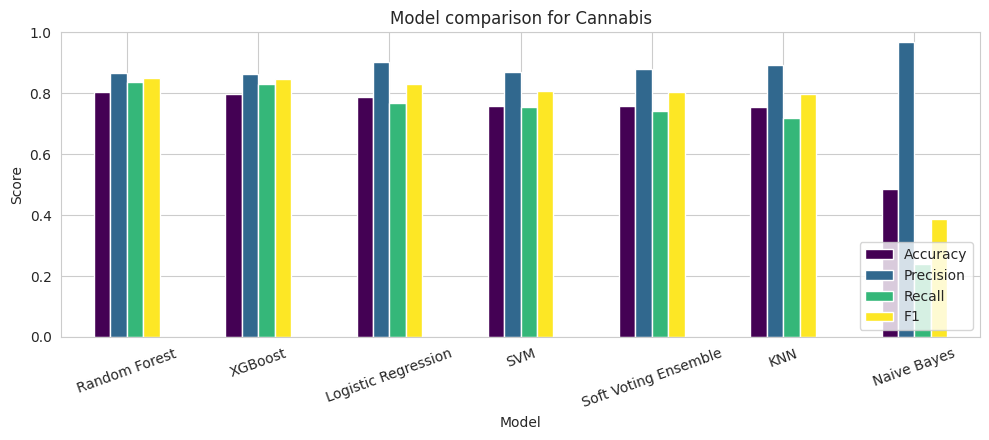

In [11]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 4.5), colormap="viridis")
plt.title(f"Model comparison for {TARGET}")
plt.ylabel("Score"); plt.ylim(0, 1); plt.xticks(rotation=20); plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Random Forest came out on top, so that's the model we'll explain with SHAP and LIME.

In [12]:
EXPLAIN_MODEL = best_models["Random Forest"]

## 9. SHAP: what matters overall

SHAP gives every feature, for every prediction, a number that says how much it pushed
that prediction toward "User" (positive) or "Non-user" (negative). Averaging the
size of that number across all 377 test participants gives us a ranking of what
matters most overall.

In [13]:
shap_explainer = shap.TreeExplainer(EXPLAIN_MODEL)
shap_values_raw = shap_explainer.shap_values(X_test_sel)

if isinstance(shap_values_raw, list):
    shap_values = shap_values_raw[1]
elif shap_values_raw.ndim == 3:
    shap_values = shap_values_raw[:, :, 1]
else:
    shap_values = shap_values_raw

shap_df = pd.DataFrame(shap_values, index=X_test_sel.index, columns=X_test_sel.columns)
shap_global = shap_df.abs().mean().sort_values(ascending=False)
print("Top 10 features by SHAP:")
print(shap_global.head(10).round(4))

Top 10 features by SHAP:
Country_UK       0.1005
Age_ord          0.0994
SS               0.0714
Oscore           0.0591
Country_USA      0.0537
Cscore           0.0366
Education_ord    0.0279
Gender_bin       0.0257
Impulsive        0.0209
AScore           0.0174
dtype: float64


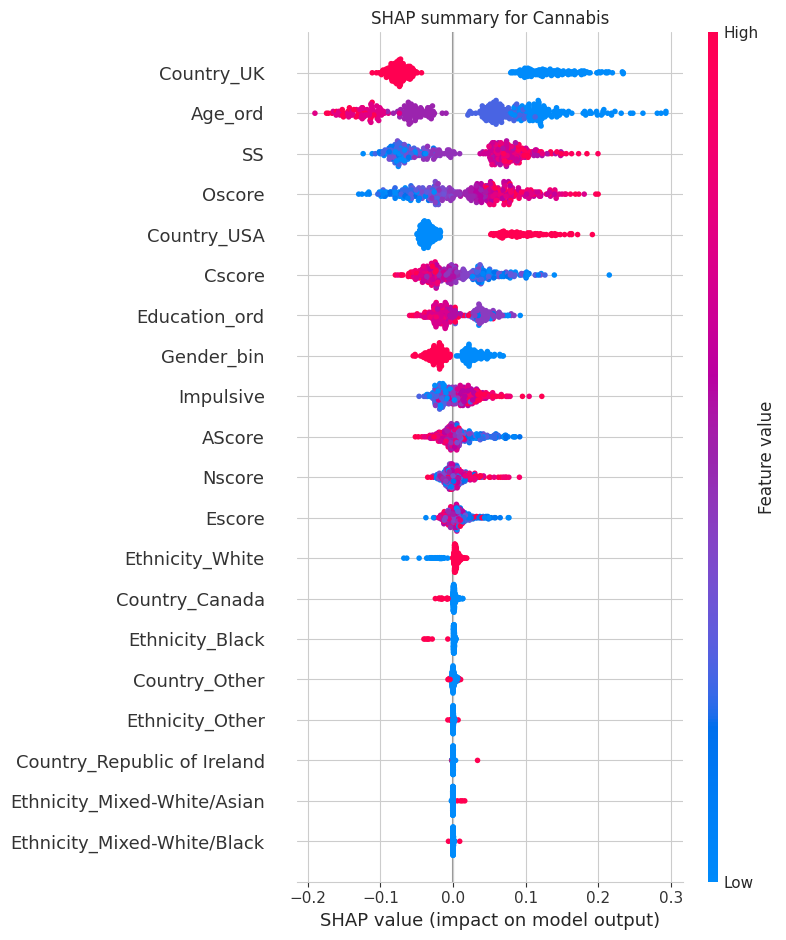

In [14]:
shap.summary_plot(shap_values, X_test_sel, show=False)
plt.title(f"SHAP summary for {TARGET}")
plt.tight_layout()
plt.show()

## 10. LIME: what matters for one person at a time

LIME works differently: instead of one global explanation, it zooms in around a
single participant and fits a simple local model just to explain that one
prediction. We run it on every single test participant (not just a few examples),
so we can fairly compare it to SHAP later.

In [15]:
lime_explainer = LimeTabularExplainer(
    X_train_sel.values, feature_names=selected_features, class_names=["Non-user", "User"],
    mode="classification", discretize_continuous=True, random_state=RANDOM_STATE,
)

n_feat = len(selected_features)
lime_matrix = np.zeros((len(X_test_sel), n_feat))
for i in range(len(X_test_sel)):
    exp = lime_explainer.explain_instance(X_test_sel.values[i], EXPLAIN_MODEL.predict_proba, num_features=n_feat, labels=(1,))
    for feat_idx, weight in exp.as_map()[1]:
        lime_matrix[i, feat_idx] = weight

lime_df = pd.DataFrame(lime_matrix, index=X_test_sel.index, columns=selected_features)
lime_global = lime_df.abs().mean().sort_values(ascending=False)
print("Top 10 features by LIME:")
print(lime_global.head(10).round(4))

Top 10 features by LIME:
Country_USA                    0.1447
Oscore                         0.0772
SS                             0.0768
Cscore                         0.0546
Age_ord                        0.0532
Education_ord                  0.0388
Ethnicity_Mixed-Black/Asian    0.0367
AScore                         0.0270
Impulsive                      0.0254
Country_New Zealand            0.0252
dtype: float64


## 11. Do SHAP and LIME actually agree?

This is the main question of the whole notebook. We check agreement three ways:

1. **Overall ranking**: do both methods pick the same features as important?
2. **Direction**: for a given participant, do both methods agree which way a
   feature pushes the prediction?
3. **Person by person**: for each individual, how similar are the two explanations?

In [16]:
def cross_verify(shap_df, lime_df, top_n=10, eps=1e-6):
    shap_global = shap_df.abs().mean().sort_values(ascending=False)
    lime_global = lime_df.abs().mean().sort_values(ascending=False)

    global_rank_corr, _ = spearmanr(
        shap_global.rank(ascending=False),
        lime_global.reindex(shap_global.index).rank(ascending=False),
    )
    top_overlap = len(set(shap_global.head(top_n).index) & set(lime_global.head(top_n).index))

    dir_rows = []
    for col in shap_df.columns:
        s, l = shap_df[col], lime_df[col]
        mask = (s.abs() > eps) & (l.abs() > eps)
        agree = (np.sign(s[mask]) == np.sign(l[mask])).mean() * 100 if mask.sum() else np.nan
        dir_rows.append({"Feature": col, "N": int(mask.sum()), "Agreement_%": agree})
    direction_df = pd.DataFrame(dir_rows).sort_values("Agreement_%", ascending=False)

    row_corrs = np.array([spearmanr(shap_df.iloc[i], lime_df.iloc[i])[0] for i in range(len(shap_df))])

    return {
        "shap_global": shap_global, "lime_global": lime_global,
        "global_rank_corr": global_rank_corr, "top_overlap": top_overlap, "top_n": top_n,
        "direction_df": direction_df, "row_corrs": row_corrs,
        "mean_local_corr": np.nanmean(row_corrs),
        "pct_local_gt_0.5": (row_corrs > 0.5).mean() * 100,
    }

cv_cannabis = cross_verify(shap_df, lime_df)
print(f"Global rank correlation: {cv_cannabis['global_rank_corr']:.2f}")
print(f"Top-10 overlap: {cv_cannabis['top_overlap']}/10 features shared")
print(f"Average per-person correlation: {cv_cannabis['mean_local_corr']:.2f}")
print(f"% of people where the two methods agree well (corr > 0.5): {cv_cannabis['pct_local_gt_0.5']:.0f}%")

Global rank correlation: 0.37
Top-10 overlap: 8/10 features shared
Average per-person correlation: 0.55
% of people where the two methods agree well (corr > 0.5): 64%


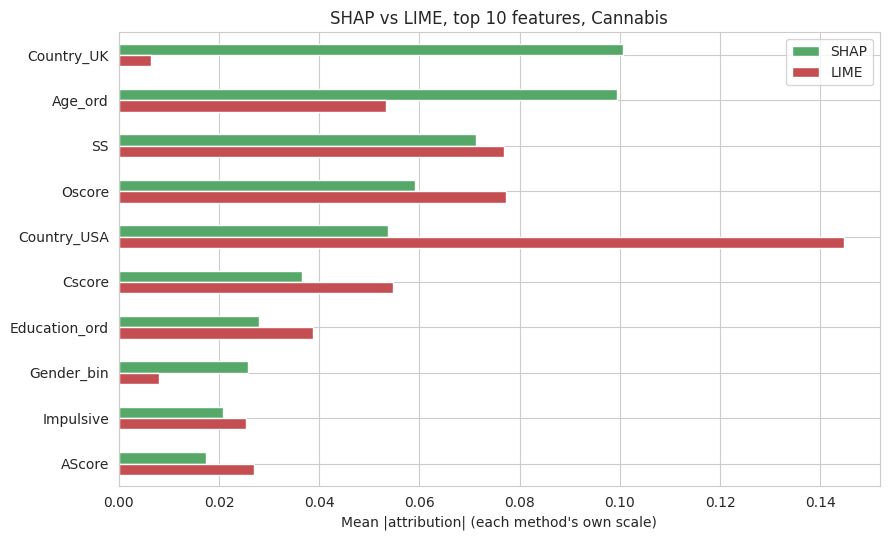

In [17]:
fig, ax = plt.subplots(figsize=(9, 5.5))
top_feats = cv_cannabis["shap_global"].head(10).index
pd.DataFrame({"SHAP": cv_cannabis["shap_global"].reindex(top_feats),
              "LIME": cv_cannabis["lime_global"].reindex(top_feats)}).plot(
    kind="barh", ax=ax, color=["#55A868", "#C44E52"])
ax.invert_yaxis()
ax.set_xlabel("Mean |attribution| (each method's own scale)")
ax.set_title(f"SHAP vs LIME, top 10 features, {TARGET}")
plt.tight_layout()
plt.show()

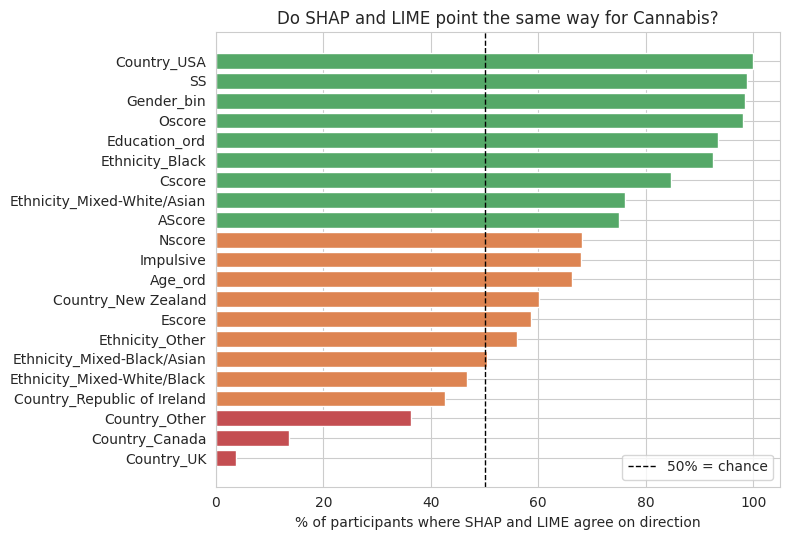

In [18]:
dd = cv_cannabis["direction_df"].dropna(subset=["Agreement_%"])
colors = ["#55A868" if v >= 70 else ("#DD8452" if v >= 40 else "#C44E52") for v in dd["Agreement_%"]]
plt.figure(figsize=(8, 5.5))
plt.barh(dd["Feature"], dd["Agreement_%"], color=colors)
plt.axvline(50, color="black", linestyle="--", linewidth=1, label="50% = chance")
plt.xlabel("% of participants where SHAP and LIME agree on direction")
plt.title(f"Do SHAP and LIME point the same way for {TARGET}?")
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Personality traits like Sensation-Seeking, Openness and Conscientiousness show
strong agreement. Both methods usually point the same direction for a given person.
The Country dummy variables are the opposite story: both methods think they matter,
but they often disagree on which way they push the prediction. So the personality
side of the model is the trustworthy part; the demographic dummies are shakier.

### A couple of real examples

Numbers are one thing, but it's easier to see what "agreement" and "disagreement"
actually look like for a real person. Below: the participant where SHAP and LIME
agreed the most, and the one where they disagreed the most.

In [19]:
best_i = int(np.argmax(cv_cannabis["row_corrs"]))
worst_i = int(np.argmin(cv_cannabis["row_corrs"]))

def show_person(i, label):
    idx = X_test_sel.index[i]
    actual = "User" if y_test.iloc[i] == 1 else "Non-user"
    proba = EXPLAIN_MODEL.predict_proba(X_test_sel.iloc[[i]])[0][1]
    print(f"--- {label} (corr = {cv_cannabis['row_corrs'][i]:.2f}) ---")
    print(f"Actual: {actual}, predicted probability of User: {proba:.2f}")
    print("SHAP top 3:")
    for feat, val in shap_df.iloc[i].reindex(shap_df.iloc[i].abs().sort_values(ascending=False).index).head(3).items():
        print(f"   {feat:15s} {val:+.3f}")
    print("LIME top 3:")
    for feat, val in lime_df.iloc[i].reindex(lime_df.iloc[i].abs().sort_values(ascending=False).index).head(3).items():
        print(f"   {feat:15s} {val:+.3f}")
    print()

show_person(best_i, "Best agreement")
show_person(worst_i, "Worst agreement")

--- Best agreement (corr = 0.80) ---
Actual: User, predicted probability of User: 0.84
SHAP top 3:
   SS              +0.110
   Cscore          +0.100
   Education_ord   +0.077
LIME top 3:
   Country_USA     -0.142
   SS              +0.136
   Cscore          +0.096

--- Worst agreement (corr = 0.15) ---
Actual: User, predicted probability of User: 1.00
SHAP top 3:
   Age_ord         +0.110
   Country_UK      +0.103
   Country_USA     +0.067
LIME top 3:
   Country_USA     +0.148
   SS              +0.131
   Impulsive       +0.065



# Part 2: One drug category, Depressants

The dataset has 18 individual substances, which is a lot to look at one by one. So we
grouped them into three categories (Hallucinogens, Stimulants, and Depressants) and
picked one, **Depressants** (Benzodiazepines, Heroin, Methadone), to run the exact same
pipeline on. A participant counts as a "user" of the category if they use any one of
the three substances in it.

We already know the pipeline works from Part 1, so this section is shorter. Same
steps, less commentary.

Depressants users: 0.447


Accuracy:  0.703
Precision: 0.682
Recall:    0.625
F1:        0.652


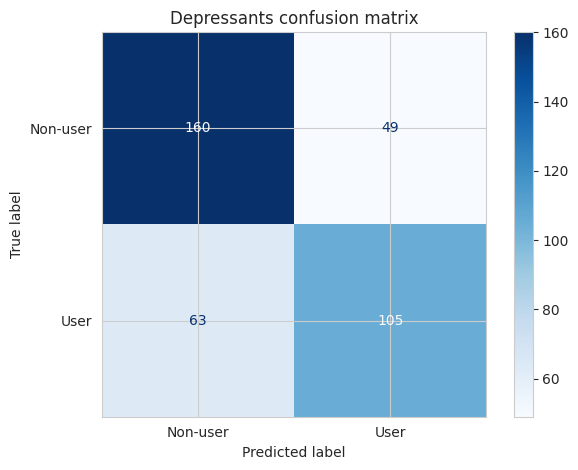

In [20]:
category_cols = ["Benzos", "Heroin", "Meth"]
y_cat = data[category_cols].isin(USER_CLASSES).any(axis=1).astype(int)
print("Depressants users:", y_cat.mean().round(3))

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    feature_frame, y_cat, test_size=0.2, stratify=y_cat, random_state=RANDOM_STATE
)
cat_scaler = StandardScaler()
Xc_train_s = pd.DataFrame(cat_scaler.fit_transform(Xc_train), columns=feature_frame.columns, index=Xc_train.index)
Xc_test_s = pd.DataFrame(cat_scaler.transform(Xc_test), columns=feature_frame.columns, index=Xc_test.index)
Xc_bal, yc_bal = SMOTE(random_state=RANDOM_STATE).fit_resample(Xc_train_s, yc_train)

cat_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
cat_model.fit(Xc_bal, yc_bal)
cat_pred = cat_model.predict(Xc_test_s)

print(f"Accuracy:  {accuracy_score(yc_test, cat_pred):.3f}")
print(f"Precision: {precision_score(yc_test, cat_pred):.3f}")
print(f"Recall:    {recall_score(yc_test, cat_pred):.3f}")
print(f"F1:        {f1_score(yc_test, cat_pred):.3f}")

cm = confusion_matrix(yc_test, cat_pred)
ConfusionMatrixDisplay(cm, display_labels=["Non-user", "User"]).plot(cmap="Blues")
plt.title("Depressants confusion matrix")
plt.tight_layout()
plt.show()

In [21]:
cat_shap_explainer = shap.TreeExplainer(cat_model)
cat_sv_raw = cat_shap_explainer.shap_values(Xc_test_s)
cat_sv = cat_sv_raw[:, :, 1] if cat_sv_raw.ndim == 3 else (cat_sv_raw[1] if isinstance(cat_sv_raw, list) else cat_sv_raw)
cat_shap_df = pd.DataFrame(cat_sv, index=Xc_test_s.index, columns=feature_frame.columns)

cat_lime_explainer = LimeTabularExplainer(
    Xc_train_s.values, feature_names=feature_frame.columns.tolist(), class_names=["Non-user", "User"],
    mode="classification", random_state=RANDOM_STATE,
)
n_feat_cat = feature_frame.shape[1]
cat_lime_mat = np.zeros((len(Xc_test_s), n_feat_cat))
for i in range(len(Xc_test_s)):
    exp = cat_lime_explainer.explain_instance(Xc_test_s.values[i], cat_model.predict_proba, num_features=n_feat_cat, labels=(1,))
    for feat_idx, weight in exp.as_map()[1]:
        cat_lime_mat[i, feat_idx] = weight
cat_lime_df = pd.DataFrame(cat_lime_mat, index=Xc_test_s.index, columns=feature_frame.columns)

cv_depressants = cross_verify(cat_shap_df, cat_lime_df, top_n=8)
print(f"Global rank correlation: {cv_depressants['global_rank_corr']:.2f}")
print(f"Top-8 overlap: {cv_depressants['top_overlap']}/8 features shared")
print(f"Average per-person correlation: {cv_depressants['mean_local_corr']:.2f}")
print(f"% of people where the two methods agree well (corr > 0.5): {cv_depressants['pct_local_gt_0.5']:.0f}%")

Global rank correlation: 0.74
Top-8 overlap: 6/8 features shared
Average per-person correlation: 0.73
% of people where the two methods agree well (corr > 0.5): 96%


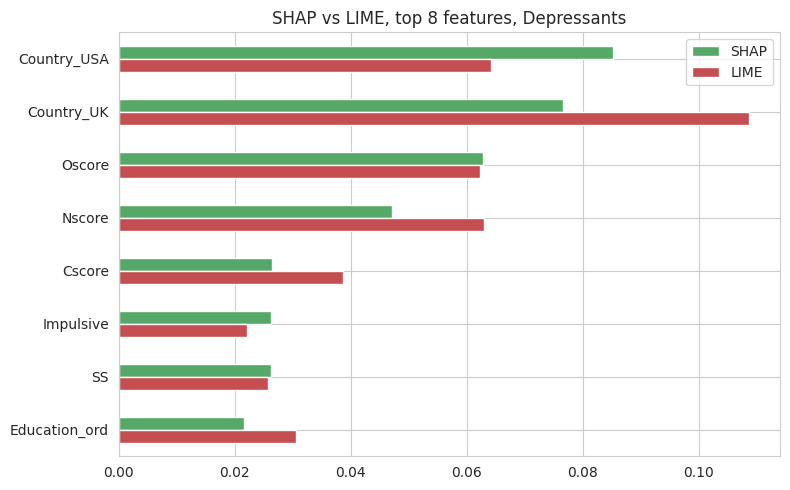

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
top_feats = cv_depressants["shap_global"].head(8).index
pd.DataFrame({"SHAP": cv_depressants["shap_global"].reindex(top_feats),
              "LIME": cv_depressants["lime_global"].reindex(top_feats)}).plot(
    kind="barh", ax=ax, color=["#55A868", "#C44E52"])
ax.invert_yaxis()
ax.set_title("SHAP vs LIME, top 8 features, Depressants")
plt.tight_layout()
plt.show()

Depressants actually shows *stronger* SHAP/LIME agreement than Cannabis did.
Both the overall ranking and the person-by-person correlation are higher. So the two
explanation methods don't just agree or disagree in general; how well they agree
depends on the specific drug being predicted.

## 12. Wrap-up

**Cannabis:** Random Forest was the best model (see Part 1 for exact numbers). SHAP and
LIME mostly agree on what matters (8 of their top 10 features overlap) and they agree
especially well on the personality traits (Sensation-Seeking, Openness,
Conscientiousness). Where they disagree is on the Country features: both flag them as
important, but disagree about which direction they push a given prediction.

**Depressants:** the same pipeline, same explanation methods, and the SHAP/LIME agreement
was even stronger here than for Cannabis.

**Bottom line:** SHAP and LIME aren't identical, and shouldn't be treated as
interchangeable. But when it comes to the personality-trait features, the part of this
model that's actually interesting from a behavioural standpoint, they tell a
consistent story, which is what makes that part of the result trustworthy. The
demographic dummy variables are the part to be more careful about.

This is all built from a one-time self-report survey, so everything here is an
association, not a cause, and none of it is meant to say anything about a specific
person.